# Tutorial 06: jit, gradients and numpyro

The first five chapters reproduced *what* FastOmega computes. This chapter is about *how to use it*, and why it is **differentiable**:

| Section | Content |
|---|---|
| 1 | what `make()` does; jit compilation and **re-compilation** |
| 2 | gradients: `jax.grad` / `jax.jacrev`, compared parameter by parameter with finite differences |
| 3 | timing: one evaluation vs evaluation + gradient vs the full Jacobian |
| 4 | why soft edges: a control experiment with a hard mass cut |
| 5 | a minimal numpyro NUTS example |

(The numbers of sections 2 and 3 can go straight into the "differentiable" section of the paper.)

In [1]:
import os
for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[k] = "1"
    
%matplotlib inline
import sys
sys.path.append("../")
FIGDIR = "../../Figures/"

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import numpyro
numpyro.enable_x64()                        # same as jax_enable_x64; must come before any JAX work
import seaborn as sns
sns.set(style='ticks', context='notebook', font='serif', 
        font_scale=1.5, palette='deep')
plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amssymb}\usepackage{mathrsfs}\usepackage{bm}", 
    "font.family": "serif",
    'backend': 'pdf',
    # Grid
    "axes.grid": True,
    "grid.alpha": 0.7,
    "grid.linewidth": 0.4,

    # Ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    # Font
    'font.size': 18,
    'legend.fontsize': 18,
})
import jax
import jax.numpy as jnp

from stochaxtic import jax_populations as jp
from stochaxtic.fast_omega import FastOmega, T_SUN, A_PRE
from stochaxtic.constants import H0_SI

fo = FastOmega()                            # BBH, no spins (chapters 01-03)
mass, rate = "bpl_double_gaussian", "madau_dickinson"

/home/haowen.zhong/.conda/envs/Hierfit/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FastOmega: building the IMRPhenomXAS table: 121 spin/q columns x 1 tide nodes (1 kappa x 1 split), 1005 frequencies each, 0.00 GB on disk ...


/home/haowen.zhong/StochAXtic/StochAXtic/tutorials/../stochaxtic/orientation.py:103: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


FastOmega: table built in 0 s, cached at /home/haowen.zhong/.cache/stochaxtic/jtable_IMRPhenomXAS_0cca5f8ae6cef218.npy
FastOmega: SVD of 121 columns in 0 s
FastOmega: IMRPhenomXAS, spins=None, tides=False: 121 table columns, rank 8; grids lnM 1231, z 444, lnq 121, lnf 1061; setup 0.7 s


## 1. `make()` and jit

`make(mass, rate, ...)` does three things:
1. it checks the model names, builds the mass sub-grid in advance, and runs `check_support` on the **default** parameters (it warns if the population leaks out of the grid); with spins it also runs `check_spins`;
2. for `rate="madau_dickinson_timedelay"` it builds the time-delay model (`TimeDelayedMadauDickinson`) for this FastOmega's cosmology in advance: its tables depend only on the cosmology, not on the redshift grid or the hyperparameters, and it can be called at any $z$;
3. it returns a closure wrapped in `@jax.jit`, `omega(mass_params, rate_params, spin_params, tide_params)`, which calls the `fo.omega(...)` reproduced line by line in chapter 03.

**The jit rule**: on the first call JAX traces the whole computation and compiles it into an XLA program. Afterwards, as long as the **structure** of the inputs (which keys, which array shapes) stays the same, the compiled program runs directly. A change in the **set of keys** of a parameter dict triggers a re-compilation, so in an MCMC pass the same set of keys at every step.

In [3]:
om = fo.make(mass, rate)

def timed(f, *a, n=1):
    t = time.perf_counter()
    for _ in range(n):
        out = jax.block_until_ready(f(*a))
    return out, (time.perf_counter() - t) / n

_, t0 = timed(om, {"alpha_m_1": 1.6}, {"R0": 18.0})
_, t1 = timed(om, {"alpha_m_1": 1.7}, {"R0": 19.0}, n=50)
_, t2 = timed(om, {"alpha_m_1": 1.7, "m_break": 40.0}, {"R0": 19.0})       # new key -> re-trace + compile
_, t3 = timed(om, {"alpha_m_1": 1.8, "m_break": 41.0}, {"R0": 19.0}, n=50)
print(f"first call (trace + compile): {t0:7.3f} s")
print(f"same keys, new values:        {t1 * 1e3:7.2f} ms")
print(f"one more key (re-compile):    {t2:7.3f} s")
print(f"then again:                   {t3 * 1e3:7.2f} ms")

first call (trace + compile):   0.641 s
same keys, new values:           2.28 ms
one more key (re-compile):      0.547 s
then again:                      3.28 ms


## 2. Gradients: automatic differentiation vs finite differences

Collect the hyperparameters into a vector $\boldsymbol\theta$ (here all 15 mass parameters of BPL+2G and the 4 redshift parameters of Madau–Dickinson) and compute the Jacobian of $\ln\Omega(f)$ at a few frequencies:

- **automatic differentiation**: `jax.jacrev`, reverse mode; one backward pass per output gives the derivatives with respect to all parameters;
- **finite differences**: a central difference for each parameter, with $h=10^{-5}|\theta_a|$.

The two should agree to the accuracy of the finite differences ($\sim h^2$ plus round-off).

In [4]:
mkeys = list(jp.MASS_MODELS[mass][1])
rkeys = list(jp.RATE_DEFAULTS[rate])
theta0 = jnp.array([jp.MASS_MODELS[mass][1][k] for k in mkeys] + [jp.RATE_DEFAULTS[rate][k] for k in rkeys])
fsel = np.array([np.argmin(np.abs(fo.freqs - f)) for f in (25.0, 100.0, 400.0)])

def ln_omega(theta):
    mp = {k: theta[i] for i, k in enumerate(mkeys)}
    rp = {k: theta[len(mkeys) + i] for i, k in enumerate(rkeys)}
    return jnp.log(om(mp, rp)[fsel])

J_ad = jax.jacrev(ln_omega)(theta0)                          # (3 freqs, 19 params)

J_fd = np.zeros_like(np.asarray(J_ad))
for a in range(len(theta0)):
    h = 1e-5 * abs(float(theta0[a]))
    e = jnp.zeros_like(theta0).at[a].set(h)
    J_fd[:, a] = (np.asarray(ln_omega(theta0 + e)) - np.asarray(ln_omega(theta0 - e))) / (2 * h)

print(f"{'parameter':15s} {'dlnOmega/dtheta (100 Hz)':>26s}  {'AD vs FD (max over f)':>22s}")
for a, k in enumerate(mkeys + rkeys):
    scale = np.max(np.abs(J_ad[:, a])) + 1e-30
    print(f"{k:15s} {float(J_ad[1, a]):26.4e}  {np.max(np.abs(J_ad[:, a] - J_fd[:, a])) / scale:22.1e}")

parameter         dlnOmega/dtheta (100 Hz)   AD vs FD (max over f)
alpha_m_1                      -3.1379e-01                 2.9e-10
alpha_m_2                      -1.0218e-02                 1.1e-09
beta_q                          8.8014e-02                 7.9e-10
m_break                         7.0716e-03                 1.9e-10
mu_m_1                          4.1498e-02                 2.7e-10
sigma_m_1                       2.3395e-03                 1.1e-08
mu_m_2                          2.2688e-03                 5.9e-10
sigma_m_2                      -1.0810e-03                 2.1e-08
m_1_min                         6.9120e-02                 7.5e-10
m_max                          -3.4135e-08                 8.7e-07
lambda_peak_1                  -2.9968e+00                 7.2e-11
lambda_peak_2                  -3.8410e+00                 7.2e-11
delta_m_1                       1.8183e-02                 2.9e-09
m_2_min                         3.0941e-02                 3.2

(Relative differences of $\sim10^{-10}$–$10^{-8}$ are the accuracy limit of finite differences; automatic differentiation is exact to machine precision. A parameter far outside the bulk of the population, such as $m_{\max}=300$, has a tiny derivative ($\sim10^{-8}$), whose finite-difference estimate is limited by round-off.)

## 3. Timing

What a likelihood really needs is the gradient of a **scalar**, e.g. of a Gaussian likelihood $\ln\mathcal L=-\tfrac12\sum_k(\Omega_k-d_k)^2/\sigma_k^2$.

Automatic differentiation has two modes, and the wrong one costs orders of magnitude:
- **reverse mode** (`grad`, `jacrev`): one backward pass gives the derivatives of **one output** with respect to **all inputs**. The gradient of a scalar likelihood with respect to 19 parameters takes one pass, costing a few evaluations, independently of the number of parameters. This is exactly what NUTS needs.
- **forward mode** (`jacfwd`): one forward pass gives the derivatives of **all outputs** with respect to **one input**.

For the full Jacobian $\partial\Omega_k/\partial\theta_a$ (996 frequencies × 19 parameters, as needed for a Fisher matrix), reverse mode needs 996 passes and forward mode only 19. **Many outputs and few parameters: use `jacfwd`**.

In [5]:
data = np.asarray(om()) * 1.01
sigma = 0.05 * data

def lnL(theta):
    mp = {k: theta[i] for i, k in enumerate(mkeys)}
    rp = {k: theta[len(mkeys) + i] for i, k in enumerate(rkeys)}
    return -0.5 * jnp.sum(((om(mp, rp) - data) / sigma) ** 2)

f_val = jax.jit(lnL)
f_grad = jax.jit(jax.value_and_grad(lnL))
om_vec = lambda th: om({k: th[i] for i, k in enumerate(mkeys)}, {k: th[len(mkeys) + i] for i, k in enumerate(rkeys)})
f_jfwd = jax.jit(jax.jacfwd(om_vec))
f_jrev = jax.jit(jax.jacrev(om_vec))
for f in (f_val, f_grad, f_jfwd, f_jrev):          # compile
    jax.block_until_ready(f(theta0))
_, tv = timed(f_val, theta0, n=100)
_, tg = timed(f_grad, theta0, n=100)
Jf, tjf = timed(f_jfwd, theta0, n=5)
Jr, tjr = timed(f_jrev, theta0, n=1)
print(f"log-likelihood:                        {tv * 1e3:8.2f} ms")
print(f"log-likelihood + gradient (19 params): {tg * 1e3:8.2f} ms   ({tg / tv:.1f} x)")
print(f"Jacobian {len(fo.freqs)} x 19, forward  (jacfwd): {tjf * 1e3:8.1f} ms")
print(f"Jacobian {len(fo.freqs)} x 19, reverse  (jacrev): {tjr * 1e3:8.1f} ms")
print("the two Jacobians agree to", float(jnp.max(jnp.abs(Jf - Jr)) / jnp.max(jnp.abs(Jf))))

log-likelihood:                            3.46 ms
log-likelihood + gradient (19 params):    29.36 ms   (8.5 x)
Jacobian 996 x 19, forward  (jacfwd):     44.9 ms
Jacobian 996 x 19, reverse  (jacrev):   1894.4 ms
the two Jacobians agree to 2.527229642000891e-15


## 4. Why soft edges

Many mass models have hard cuts (e.g. $m_{\max}$ of `uniform`). On a fixed grid a hard cut means "this cell is in / out":
- $\Omega(m_{\max})$ becomes a **staircase** (with steps one grid spacing wide);
- the derivative is **0** inside each step and undefined at the steps, so a gradient-based sampler cannot see this parameter at all.

FastOmega's remedy: replace the cut by a logistic function of width one sub-sampling step in $\ln m$ (`_between`, the `"_w"` entry of the parameters). $\Omega$ then varies smoothly with the position of the cut, and its derivative is meaningful everywhere. Control experiment: with the pipeline of chapter 03, scan $m_{\max}$ with `_w = 0` (hard) and with `_w = δ/n_sub` (FastOmega's choice).

d S / d m_max at m_max = 2:  hard edge 0.0    logistic edge 1.7192226387102375e-61
mean slope of the staircase over the scan: 1.723762366165512e-61


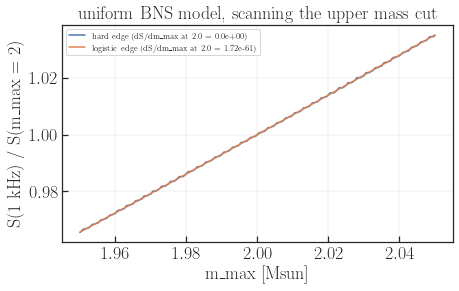

In [6]:
d = fo.info["delta"]
n_sub = 4

def omega_uniform(m_max, w_edge, i_f):
    m1, m2, jac = fo._mass_grid(n_sub)
    p = {**jp.MASS_MODELS["uniform"][1], "m_max": m_max, "_w": w_edge}
    P = jp.MASS_MODELS["uniform"][0](m1, m2, p) * jac
    P = P.reshape(fo._n_l, n_sub, -1).mean(axis=1)
    P = P / jnp.sum(P * fo._cell) * fo._cell
    P_hat = P @ fo._C[:, :, 0, 0].T
    w = fo._zw * jp.RATE_MODELS[rate](jnp.asarray(fo.z), jp.RATE_DEFAULTS[rate])
    K = jnp.fft.irfft(jnp.fft.rfft(P_hat, n=fo._L1, axis=0) * jnp.fft.rfft(w, n=fo._L1)[:, None],
                      n=fo._L1, axis=0)[:fo._n_d] * fo._e4l
    c = jnp.fft.irfft(jnp.sum(jnp.fft.rfft(K[::-1], n=fo._L2, axis=0) * fo._FJ, axis=1), n=fo._L2)
    return c[fo._n_d - 1 + i_f]                      # S on the internal ln f grid (no interpolation needed)

i_f = int(np.argmin(np.abs(np.exp(fo.lnf) - 1000.0)))
m_scan = np.linspace(1.95, 2.05, 201)
hard = np.array([float(omega_uniform(m, 0.0, i_f)) for m in m_scan])
soft = np.array([float(omega_uniform(m, d / n_sub, i_f)) for m in m_scan])
g_hard = jax.grad(lambda m: omega_uniform(m, 0.0, i_f))(2.0)
g_soft = jax.grad(lambda m: omega_uniform(m, d / n_sub, i_f))(2.0)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(m_scan, hard / hard[100], label=f"hard edge   (dS/dm_max at 2.0 = {float(g_hard):.1e})")
ax.plot(m_scan, soft / soft[100], label=f"logistic edge (dS/dm_max at 2.0 = {float(g_soft):.2e})")
ax.set(xlabel="m_max [Msun]", ylabel="S(1 kHz) / S(m_max = 2)", title="uniform BNS model, scanning the upper mass cut")
ax.legend(fontsize=8)
print("d S / d m_max at m_max = 2:  hard edge", float(g_hard), "   logistic edge", float(g_soft))
print("mean slope of the staircase over the scan:", (hard[-1] - hard[0]) / (m_scan[-1] - m_scan[0]))

With the hard cut, $S$ is constant within each grid step (zero derivative) and jumps only at the grid points; with the soft cut, $S$ varies smoothly and its derivative agrees with the mean slope of the staircase.

## 5. A minimal numpyro example

Two parameters: the BBH local rate $R_0$ and the peak redshift $z_p$, with toy noise (5% at each frequency). The $\Omega$ in the likelihood is just `om(...)`, and NUTS runs its Hamiltonian dynamics with the gradients that JAX computes automatically. A fuller example (BBH+BNS+NSBH, parallel chains, and a speed-up that uses $\Omega\propto R_0$) is `examples/numpyro_three_populations.py`.

In [8]:
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

f_obs = np.geomspace(20, 400, 30)
fo_obs = FastOmega(freqs=f_obs, verbose=False)
om_obs = fo_obs.make(mass, rate)
truth = {"R0": 18.0, "zp": 2.27}
O_true = np.asarray(om_obs(None, truth))
sig = 0.05 * O_true
obs = O_true + sig * np.random.default_rng(3).standard_normal(len(f_obs))

def model(obs):
    R0 = numpyro.sample("R0", dist.Uniform(1.0, 100.0))
    zp = numpyro.sample("zp", dist.Uniform(0.5, 5.0))
    numpyro.sample("obs", dist.Normal(om_obs(None, {"R0": R0, "zp": zp}), sig), obs=obs)

t = time.time()
mcmc = MCMC(NUTS(model), num_warmup=300, num_samples=600, progress_bar=True)
mcmc.run(jax.random.PRNGKey(0), obs)
print(f"NUTS: {time.time() - t:.1f} s")
mcmc.print_summary()

sample: 100%|██████████| 900/900 [00:10<00:00, 86.98it/s, 17 steps of size 1.26e-01. acc. prob=0.95] 

NUTS: 11.8 s

                mean       std    median      5.0%     95.0%     n_eff     r_hat
        R0     18.88      0.86     18.86     17.44     20.31    100.57      1.00
        zp      2.17      0.10      2.17      1.98      2.32     84.41      1.00

Number of divergences: 0


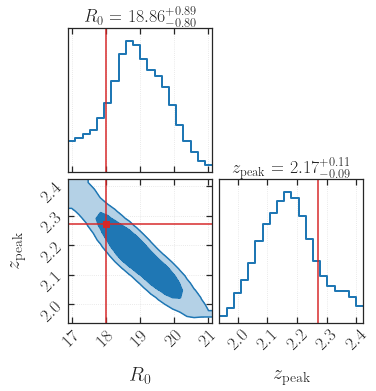

In [10]:
import corner

fig = corner.corner(
    mcmc.get_samples(),
    truths=dict(R0=17.99719280349701,zp=2.270700222839242),
    labels=[r"$R_0$", r"$z_{\mathrm{peak}}$"],
    label_kwargs={"fontsize": 20},
    title_kwargs={"fontsize": 18},
    truth_color="tab:red",
    truth_linestyle="--",
    color="tab:blue",
    show_titles=True,
    title_fmt=".2f",
    hist_kwargs={"linewidth": 2},  # ← remove 'density'
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95),
    smooth=1.0,
    smooth1d=1.0,
    max_n_ticks=5,
)

K = 2
axes = np.array(fig.axes).reshape(K, K)

for i in range(K):
    for j in range(i + 1):  
        ax = axes[i, j]
        ax.tick_params(which="both", direction="in", top=True, right=True)
        ax.grid(True, linestyle=":", linewidth=0.8, alpha=0.6)
        ax.set_axisbelow(True)  
        

($R_0$ and $z_p$ are strongly correlated: the background mainly measures one combination of them, as the Fisher analysis also shows.)

## Summary: why FastOmega is differentiable by construction

1. **Fixed grids and samples**: the $\ln M$, $z$ and $q$ grids, the Sobol spin samples and the κ nodes do not change with the hyperparameters. There is no resampling, hence no random noise.
2. **The hyperparameters enter only smooth point-wise functions**: the mass density, the merger rate, the spin density, the EOS.
3. **Everything after them is linear**: weighted sums, einsum, FFTs, linear interpolation. Their derivatives with respect to the inputs are exact and cheap.
4. **A few engineering details** keep everything smooth: logistic soft edges instead of hard cuts (section 4), numerically stable forms of the Planck window and of the BPL normalisation (otherwise the gradients turn into NaN), and tide weights that are continuous piecewise polynomials of κ (cubic in $\ln\kappa$, chapter 05).

Together, these six chapters cover the whole of `fast_omega.py`.